nov 21th

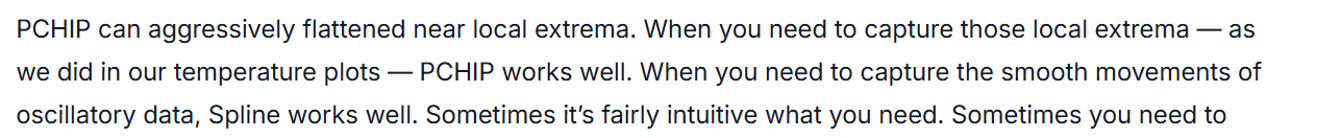

In [300]:
# import xarray as xr
# from scipy.interpolate import NearestNDInterpolator
# from scipy.interpolate import griddata
from scipy.interpolate import PchipInterpolator, pchip_interpolate

import pandas as pd
import numpy as np
# from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

### bringing in sed (TOS)

this will be the alpha dataset

In [301]:
dtos = pd.read_csv('..\\data\\mcs02\\TOS.csv', sep='\\s+', skiprows=1,
                 names=['line_name', 'x', 'y', 'lat', 'long', 'z_ms', 'z_s'])
print(dtos)

     line_name       x        y        lat        long      z_ms       z_s
0        mcs02  193122  5277091  47.574574 -127.080767  3387.986  3.387986
1        mcs02  193116  5277093  47.574589 -127.080848  3387.924  3.387924
2        mcs02  193110  5277095  47.574604 -127.080929  3387.768  3.387768
3        mcs02  193104  5277097  47.574619 -127.081010  3387.614  3.387614
4        mcs02  193098  5277099  47.574634 -127.081091  3387.520  3.387520
...        ...     ...      ...        ...         ...       ...       ...
8846     mcs02  141164  5295989  47.717401 -127.784879  3532.632  3.532632
8847     mcs02  141158  5295991  47.717416 -127.784960  3532.632  3.532632
8848     mcs02  141152  5295993  47.717431 -127.785042  3532.632  3.532632
8849     mcs02  141146  5295995  47.717445 -127.785123  3532.632  3.532632
8850     mcs02  141141  5295997  47.717460 -127.785191  3535.945  3.535945

[8851 rows x 7 columns]


### bringing in crust (TOC)

this will be the omega dataset

In [302]:
dtoc = pd.read_csv('..\\data\\mcs02\\TOC.csv', sep='\\s+', skiprows=1, 
                 names=['line_name', 'x', 'y', 'lat', 'long', 'z_ms', 'z_s'])
print(dtoc)

     line_name       x        y        lat        long      z_ms       z_s
0        mcs02  193122  5277091  47.574574 -127.080767  4506.494  4.506494
1        mcs02  193116  5277093  47.574589 -127.080848  4508.189  4.508189
2        mcs02  193110  5277095  47.574604 -127.080929  4510.482  4.510482
3        mcs02  193104  5277097  47.574619 -127.081010  4516.385  4.516385
4        mcs02  193098  5277099  47.574634 -127.081091  4525.014  4.525014
...        ...     ...      ...        ...         ...       ...       ...
8138     mcs02  141816  5295751  47.715629 -127.776021  3860.610  3.860610
8139     mcs02  141810  5295754  47.715653 -127.776103  3859.799  3.859799
8140     mcs02  141804  5295756  47.715667 -127.776184  3859.563  3.859563
8141     mcs02  141798  5295758  47.715682 -127.776265  3859.924  3.859924
8142     mcs02  141793  5295760  47.715697 -127.776334  3859.273  3.859273

[8143 rows x 7 columns]


c=x, s=z

In [303]:
# converting directions to numpy array (replacement to .values)

c_xy = dtoc[['x','y']].to_numpy()
s_xy = dtos[['x','y']].to_numpy()

In [304]:
print(f'c_xy:\n{c_xy[0:5]}')
print(f's_xy:\n{s_xy[0:5]}')

c_xy:
[[ 193122 5277091]
 [ 193116 5277093]
 [ 193110 5277095]
 [ 193104 5277097]
 [ 193098 5277099]]
s_xy:
[[ 193122 5277091]
 [ 193116 5277093]
 [ 193110 5277095]
 [ 193104 5277097]
 [ 193098 5277099]]


In [305]:
# normalizes a 2D vector into unit vectors with a length of 1
origin=c_xy[0]
d_c = c_xy[-1] - c_xy[0]
d_c = d_c / np.hypot(*d_c)

# distance along the line for both datasets

c_dis = (c_xy - c_xy[0]) @ d_c

In [306]:
d_s = s_xy[-1] - s_xy[0]
d_s = d_s / np.hypot(*d_s)

s_dis = (s_xy - s_xy[0]) @ d_s

In [307]:
# now converting crust depths to numpy array
c_z = dtoc['z_s'].to_numpy()

In [308]:
order = np.argsort(c_dis)  # indices that sorts c from smallest to largest
c_dis, c_z = c_dis[order], c_z[order]

ensures original values are increasing and duplicates are removed (required for interp)

In [309]:
c_dis, idx = np.unique(c_dis, return_index=True)
c_z = c_z[idx]

In [310]:
print(f'min: {c_z.min()}, max: {c_z.max()}')

min: 3.859273, max: 4.656549


now we build the interpolator and evaluate at every sediment position

[pchipinterp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.PchipInterpolator.html#scipy.interpolate.PchipInterpolator)

from claude: "we fit one continuous curve through all the crust points, then reads that curve at each sediment distance (s_dis is a list of distances where you want a crust depth)"

In [311]:
interp_crust = pchip_interpolate(c_dis, c_z, s_dis)

making any values outside the range as NaNs

In [312]:
P = PchipInterpolator(c_dis, c_z, extrapolate=False)
interp_crust = P(s_dis)

In [313]:
dtos['z_crust'] = interp_crust

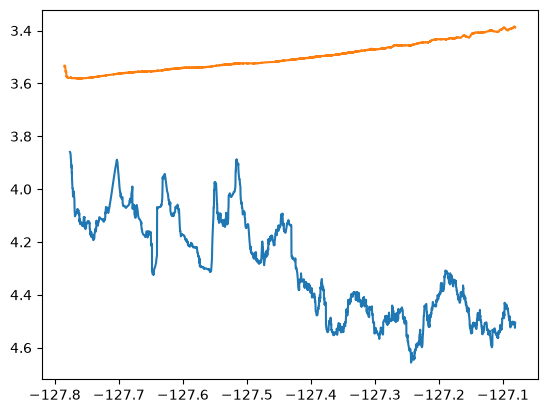

In [314]:
plt.plot(dtos['long'], dtos['z_crust'])
plt.plot(dtos['long'], dtos['z_s'])
plt.gca().invert_yaxis()
plt.show()

In [315]:
# building a new dataframe

df = pd.DataFrame({
    'x': dtos['x'],
    'y': dtos['y'],
    'long': dtos['long'],
    'lat': dtos['lat'],
    'z_sed': dtos['z_s'],
    'z_crust': dtos['z_crust']})

In [320]:
mask = (s_dis >= c_dis.min()) & (s_dis <= c_dis.max())

df['x'] = df['x'][mask]
df['y'] = df['y'][mask]
df['long'] = df['long'][mask]
df['lat'] = df['lat'][mask]
df['z_sed'] = df['z_sed'][mask]

df = df.dropna(how='all').reset_index(drop=True)

In [321]:
print(df.head())

          x          y        long        lat     z_sed   z_crust
0  193122.0  5277091.0 -127.080767  47.574574  3.387986  4.506494
1  193116.0  5277093.0 -127.080848  47.574589  3.387924  4.508189
2  193110.0  5277095.0 -127.080929  47.574604  3.387768  4.510482
3  193104.0  5277097.0 -127.081010  47.574619  3.387614  4.516385
4  193098.0  5277099.0 -127.081091  47.574634  3.387520  4.525014


In [318]:
# dtos.drop(columns=['line_name', 'z_ms', 'z_s'], inplace=True)
# print(dtos.head())

In [323]:
df.to_csv('..\\created_data\\nov23_toc_tos_interp.csv', index=False)

## old

interpolate crust [dt] at each sed [dz] point
- we have more sed [dz] than crust [dt]

> griddata(points, values, data to interp --> [scipy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.griddata.html)

In [249]:
age_interp = griddata((dtoc[['long','lat']].values), dtoc['age'].values, dtos[['long','lat']].values, method='linear')
age_nan_fill = griddata((trim_dt[['long','lat']].values), trim_dt['age'].values, dz[['long','lat']].values, method='nearest')

NameError: name 'griddata' is not defined

In [ ]:
dz['age'] = np.where(np.isnan(age_interp), age_nan_fill, age_interp)

print(dz)

            long        lat         z       age
0    -127.072914  47.572946  4586.444  4.983188
1    -127.072996  47.572970  4586.128  4.982962
2    -127.073076  47.572985  4585.567  4.982734
3    -127.073144  47.573000  4585.362  4.982544
4    -127.073225  47.573015  4586.053  4.982316
...          ...        ...       ...       ...
7456 -127.706619  47.701780  4045.076  3.476296
7457 -127.706701  47.701795  4043.890  3.476080
7458 -127.706782  47.701809  4042.803  3.475864
7459 -127.706863  47.701824  4040.274  3.475648
7460 -127.706931  47.701839  4036.368  3.475463

[7461 rows x 4 columns]


double check no nan

In [ ]:
np.where(np.isnan(dz))

NameError: name 'dz' is not defined

In [ ]:
dz[np.isclose(dz['age'], 4, atol=0.1)]  

,long,lat,z,age
4363,-127.449412,47.649997,4162.572,4.100023
4364,-127.449493,47.650012,4163.100,4.099902
4365,-127.449574,47.650027,4163.224,4.099781
4366,-127.449655,47.650042,4162.798,4.099659
4367,-127.449737,47.650057,4161.981,4.099538
...,...,...,...,...
5110,-127.512639,47.662787,3955.875,3.900994
5111,-127.512720,47.662802,3953.698,3.900748
5112,-127.512788,47.662818,3951.821,3.900533
5113,-127.512869,47.662832,3949.833,3.900287


### downloading asf

for the entire dataset

In [ ]:
dz.to_csv("..\\created_data\\nov19_long_lat_age_z.csv", index=False)

for filt data

In [ ]:
# filt_dg = dt[dt['long'].between(-129, -127) & dt['lat'].between(45, 47)]

# filt_dg.to_csv("..\\created_data\\filt_lola_grav_age_q_z_bath.csv", index=False)

            long        lat        FA
4891 -128.916670  45.100001 -8.326332
4892 -128.916670  45.216668 -4.583536
4893 -128.916670  45.333334 -5.879004
4894 -128.916670  45.450001 -4.933280
4895 -128.916670  45.566668 -5.931483
...          ...        ...       ...
7111 -127.050003  46.500001 -5.146489
7112 -127.050003  46.616668 -9.314369
7113 -127.050003  46.733334 -7.298386
7114 -127.050003  46.850001 -6.077028
7115 -127.050003  46.966668 -7.009515

[289 rows x 3 columns]
